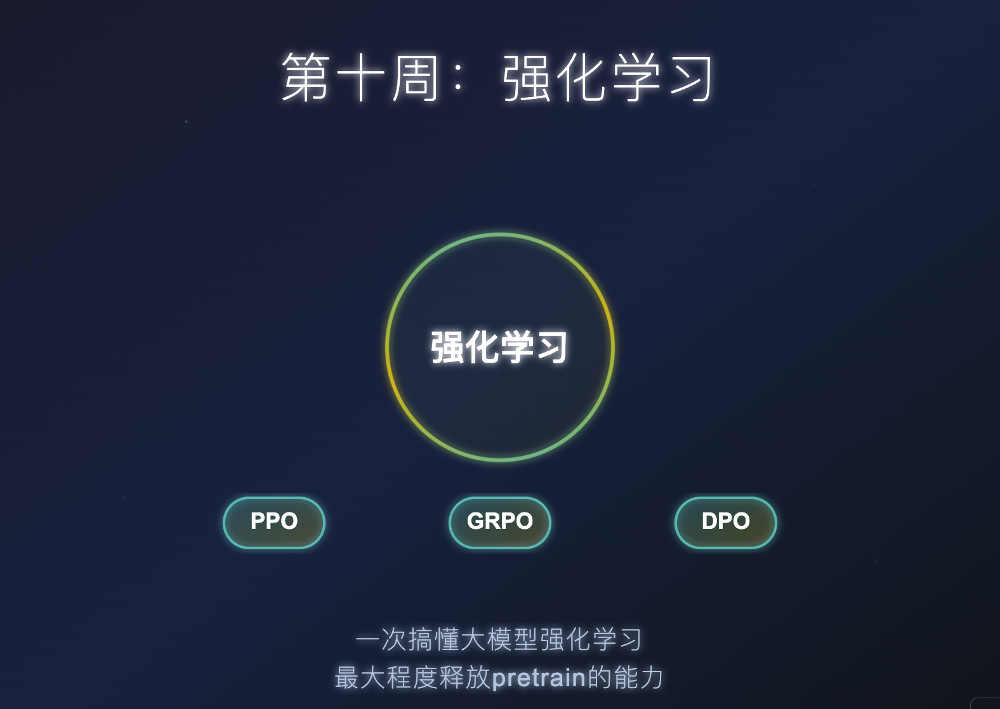

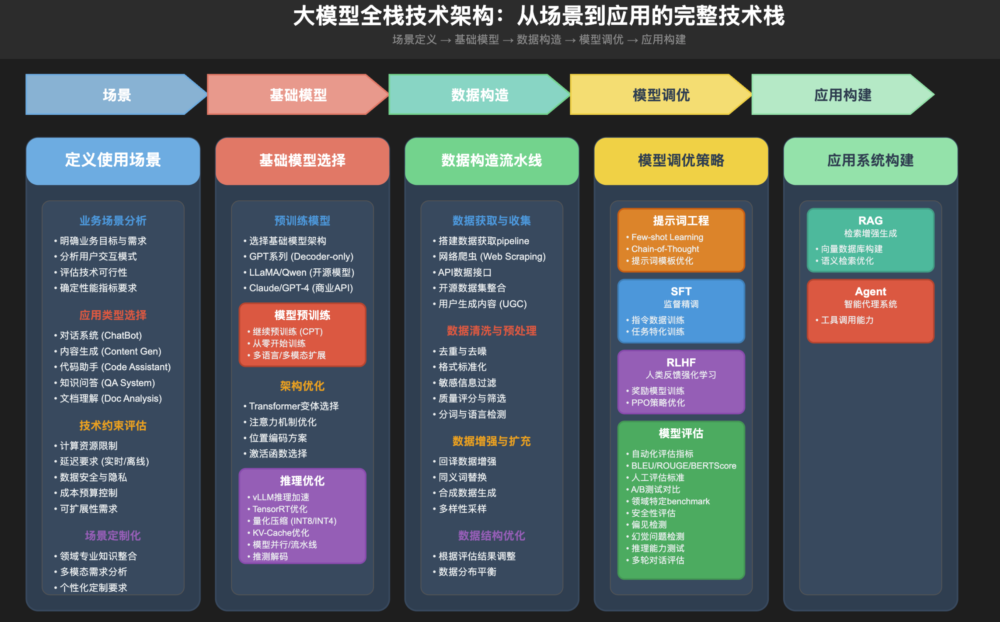

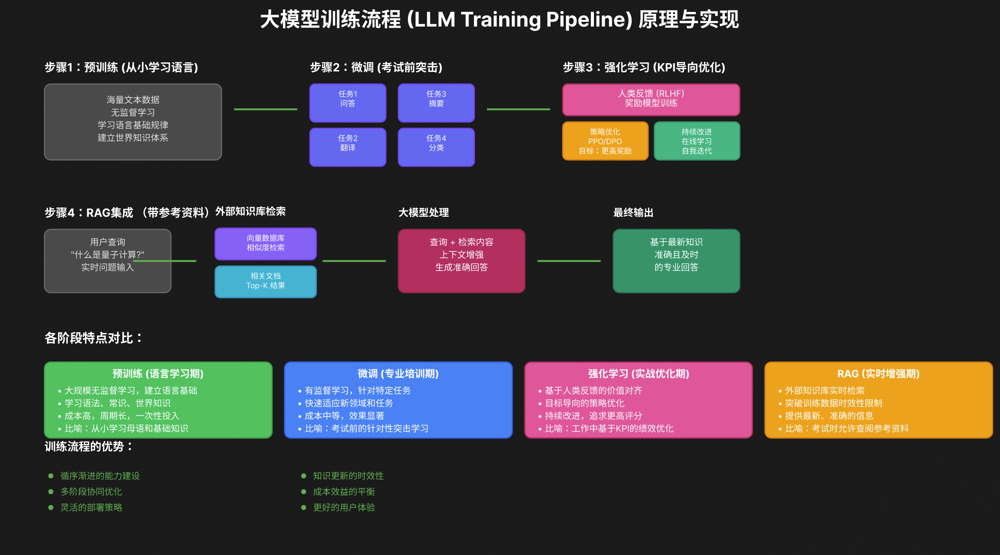

- **预训练**：从小学习语言（语言学习期）
- **微调**：考试前的突击学习（专业培训期）  
- **强化学习**：基于KPI的工作优化（实战优化期）
- **RAG**：考试、干活儿时的外挂知识库（实时增强期）

# 为什么SFT训练了还需要用RLHF？

其中多样性包含了：多目标 & 多答案

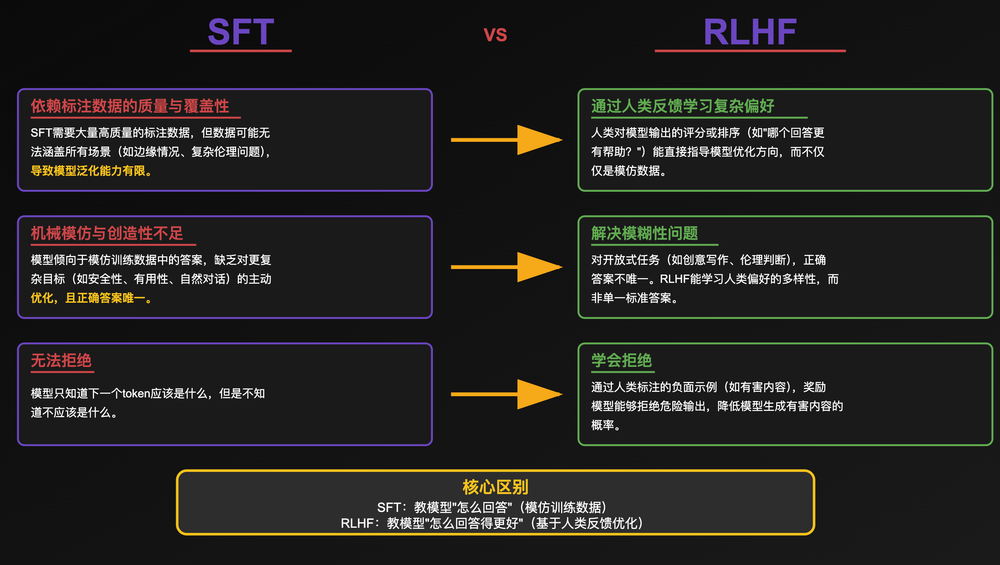

# 0.KL散度

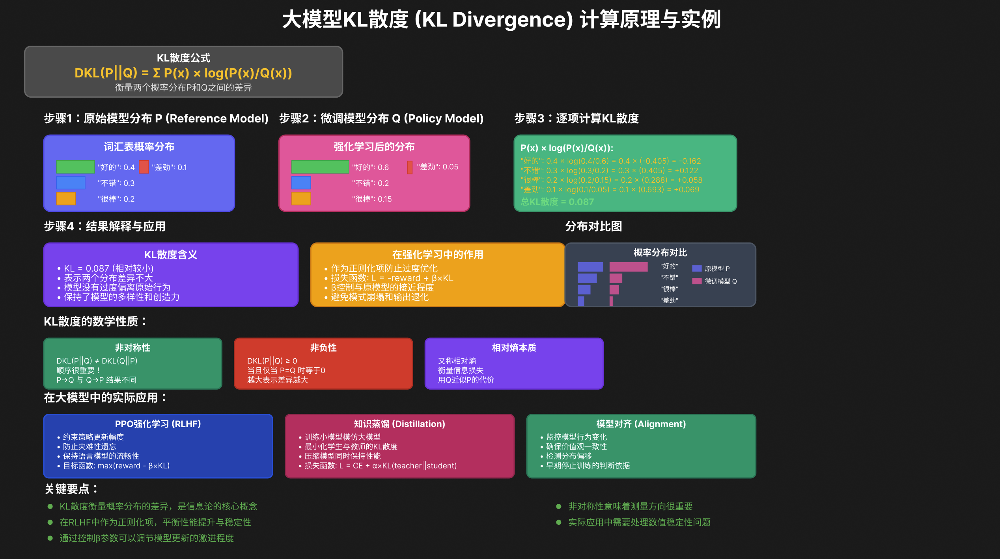

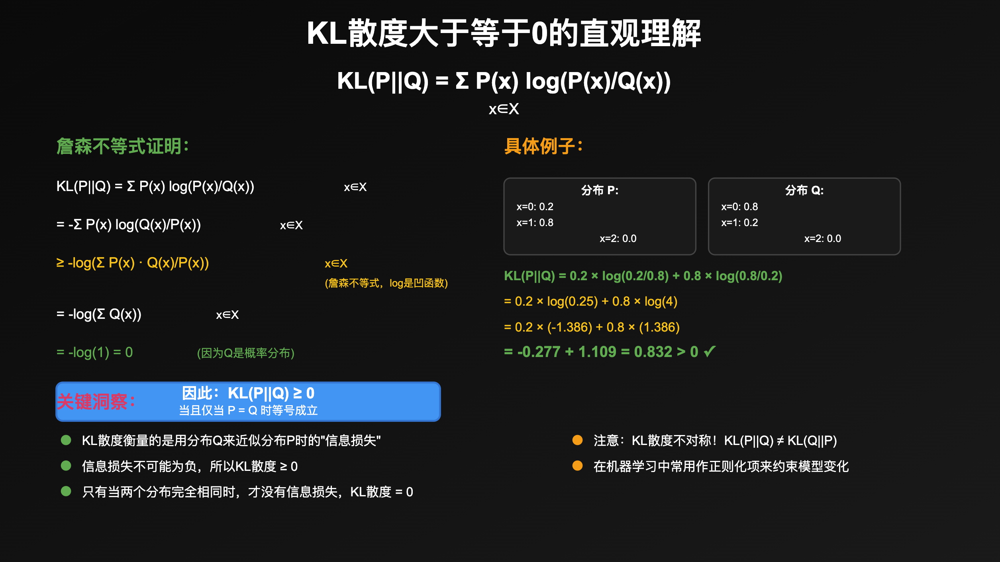

# 1.PPO

下面给出 **大语言模型 (LLM) 在 RLHF 场景下常用的 PPO 目标函数**——既包括标准 PPO 的“剪裁比值”式，也说明了 InstructGPT / TRL 等实现把 **KL 惩罚** 显式并入奖励的做法。记号一览：

| 记号                 | 含义                        |
| ------------------ | ------------------------- |
| $x$                | 提示／对话历史 (prompt)          |
| $y_{1:T}$          | 策略生成的序列                   |
| $s_t=(x,y_{<t})$   | 第 t 步的**状态**              |
| $\pi_\theta$       | 当前策略 (可训练 LLM)            |
| $\pi_{\text{old}}$ | 采样时冻结的旧策略                 |
| $\pi_{\text{ref}}$ | 参考模型（SFT 权重，梯度不更新）        |
| $R_\text{RM}(x,y)$ | 奖励模型给整条序列的打分              |
| $\beta$            | KL 系数（约 0.02 – 0.2）       |
| $\varepsilon$      | PPO clip 范围（典型 0.1 或 0.2） |

---

## A 奖励设计（sequence‑level + token‑level KL）

$$
\boxed{
r_t \;=\;
\begin{cases}
-\beta\,\bigl[\,
\log\pi_\theta(y_t\!\mid\!s_t)-\log\pi_{\text{ref}}(y_t\!\mid\!s_t)
\bigr] & \!1\le t<T\\[4pt]
R_\text{RM}(x,y)\;-\;
\beta\,\bigl[\,
\log\pi_\theta(y_T\!\mid\!s_T)-\log\pi_{\text{ref}}(y_T\!\mid\!s_T)
\bigr] & t=T
\end{cases}}
$$

* **终止步**加上来自人偏好或自动指标的标量奖励 $R_\text{RM}$。
* 每一步都累加 **KL 惩罚**，防止策略远离参考模型([Cameron R. Wolfe][1], [Hugging Face][2])。

> *如果使用“KL 直接入损失”而不是放入 $r_t$*：见下节 2.2 的等价写法。

---

## B PPO 损失

### 2.1 剪裁比值式（OpenAI Spinning‑Up / TRL 默认）

1. **概率比值**

   $$
   \rho_t(\theta)=
   \frac{\pi_\theta(y_t\mid s_t)}{\pi_{\text{old}}(y_t\mid s_t)}
   $$

2. **优势估计**（GAE）

   $$
   A_t^{(\lambda)}=\sum_{k=0}^{\infty}
   (\gamma\lambda)^{k}\,
   \bigl[r_{t+k}
        +\gamma V_{\phi}(s_{t+k+1})
        -V_{\phi}(s_{t+k})\bigr]
   $$

3. **策略损失（剪裁）**

   $$
   \mathcal L_{\text{clip}}
   =-\;
   \mathbb E_t\Bigl[
     \min\bigl(
       \rho_t A_t,\;
       \operatorname{clip}(\rho_t,1-\varepsilon,1+\varepsilon)A_t
     \bigr)
   \Bigr]
   $$

4. **价值函数损失（可选 value‑clip）**

   $$
   \mathcal L_{V}
   =\tfrac12\,
    \mathbb E_t\Bigl[
      \bigl(
        V_{\phi}(s_t)-\hat G_t
      \bigr)^{\!2}
    \Bigr],\quad
   \hat G_t=\text{MonteCarlo return}
   $$

5. **熵正则**
   $\mathcal L_{\text{ent}}=-c_{\text{ent}}\;\mathbb E_t[\,H(\pi_\theta(\,\cdot\!\mid\!s_t))]$.

> **总损失** $\displaystyle
> \mathcal L =\mathcal L_{\text{clip}}
> +c_V\mathcal L_{V}
> +\mathcal L_{\text{ent}}
> $

这种写法把 **KL 惩罚当作奖励**，因此仍可用标准 PPO clip 公式直接优化。OpenAI InstructGPT 就是此体系([Cameron R. Wolfe][1])。


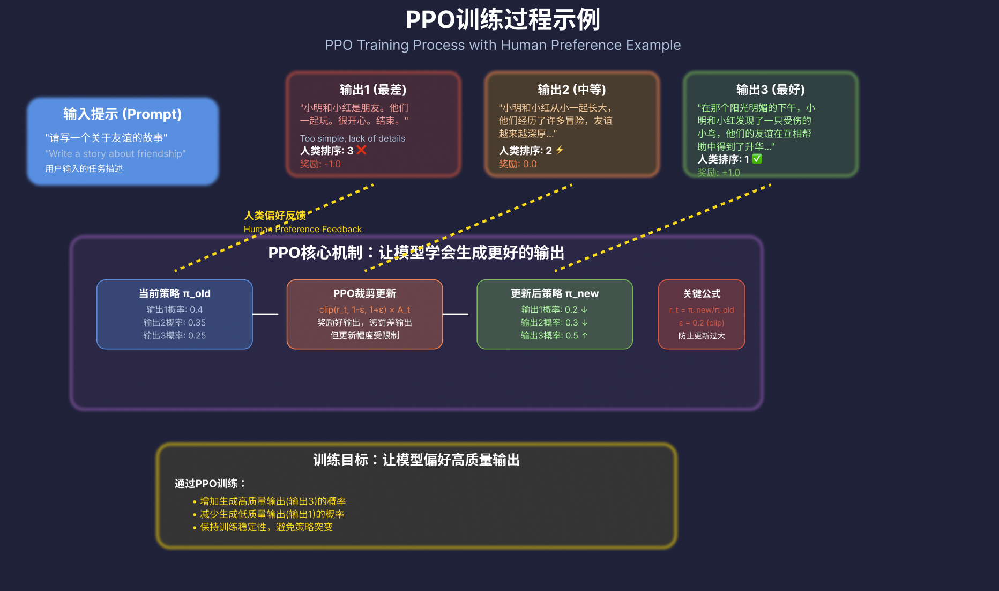

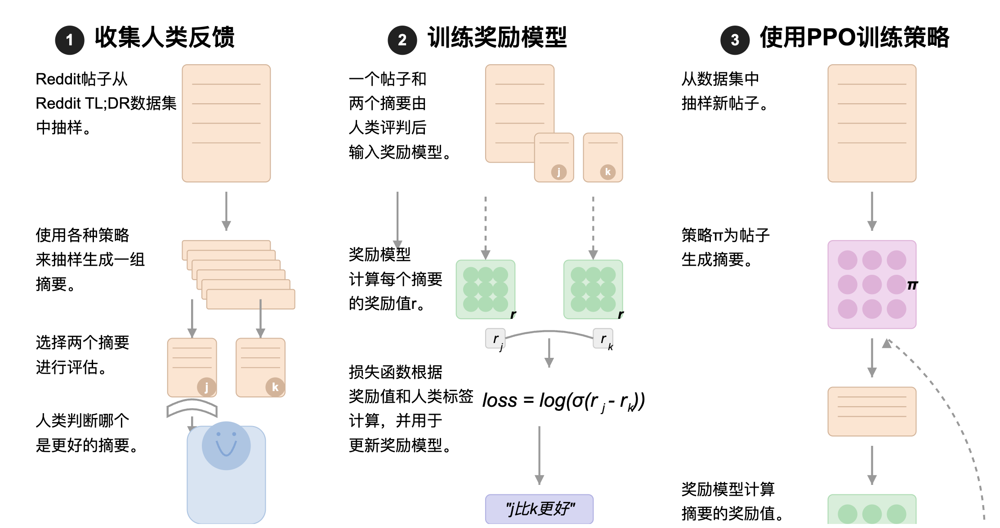

PPO 训练流程（简明版）
1. 收集人类反馈
  - 从业务日志或公开语料抽取 prompt。
  - 基模型为每个 prompt 生成多条候选回复。
  - 人类在候选中标出“更好 / 更差”（或给 1‑5 级分）。
2. 训练 Reward Model（RM）
  - 把「prompt + 更好 回答」「prompt + 更差 回答」构成 偏好对。
  - 以 pairwise 损失训练一个序列分类模型，使 r(chosen) > r(rejected)。
  - 训练好后得到可直接打分的 RM 权重。
3. PPO 策略微调
  - 使用当前策略 π 对大量 prompt 采样新回复。
  - RM 给出分数 rₜ → 转成 advantage 与旧策略分布对比，计算 PPO loss = log π/π₀ × adv(clip)。
  - 反向传播，更新策略网络参数。
  - 重复「采样→打分→更新」直到收敛。
RM 的核心意义：把多维主观偏好压缩成单标量奖励，让 PPO 能在 无需真人实时评分 的情况下迭代；RM 越稳定、越贴近业务价值，PPO 越能沿正确梯度优化。

## 1.1 Reward Model的训练 

https://oxpzcwcjtbk.feishu.cn/docx/G3SndbTInoUjFlxSRmScaDf7n4e

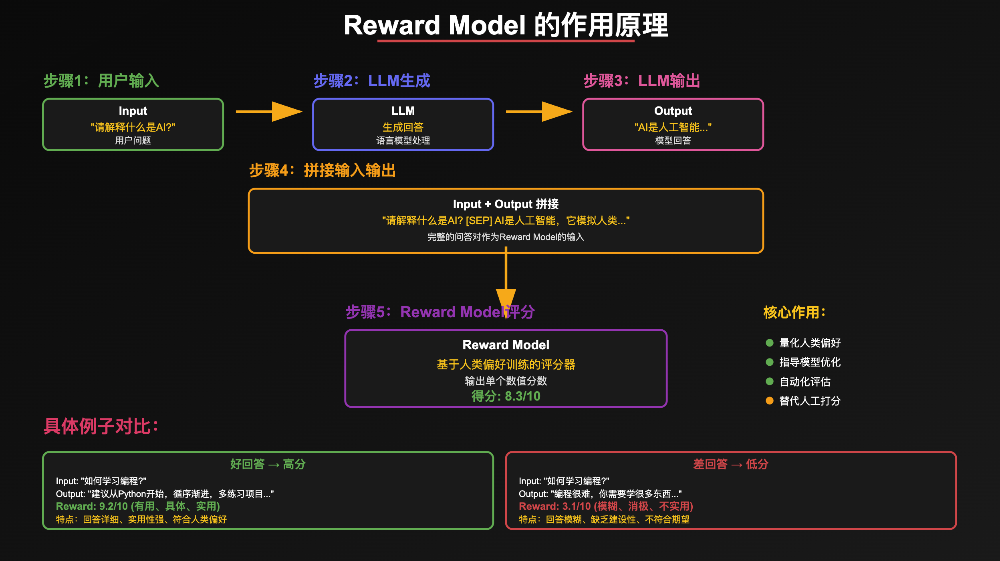

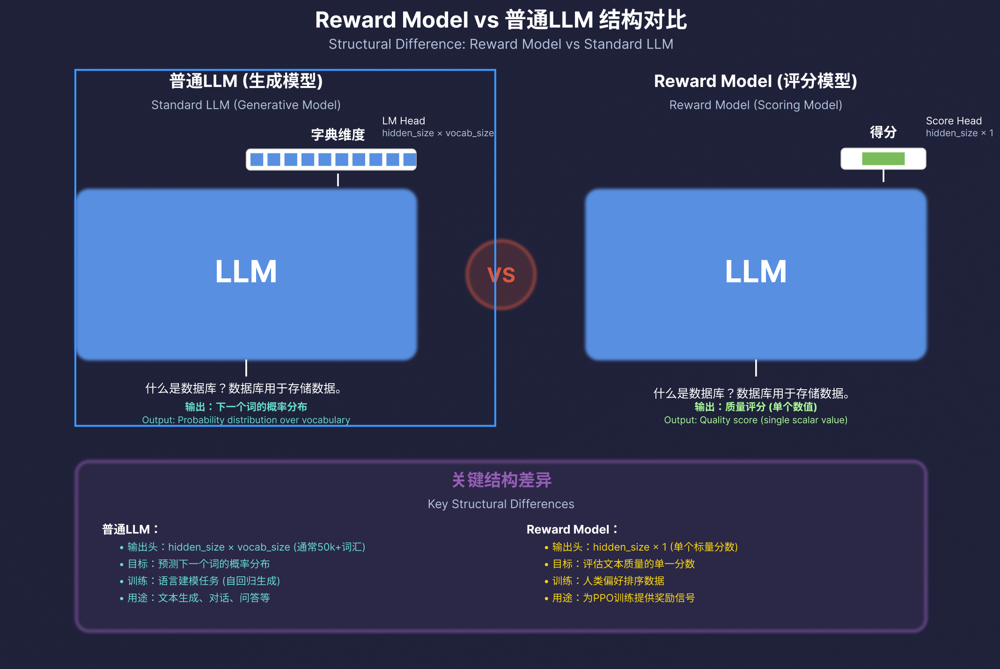

### 那这个模型怎么训练呢，人类标注评分吗？？

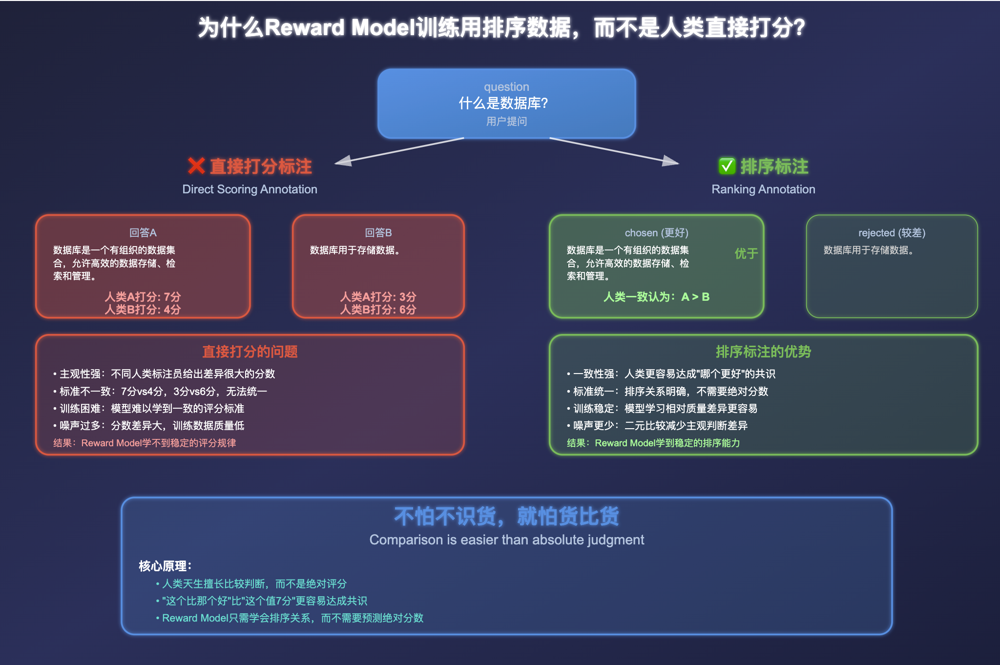

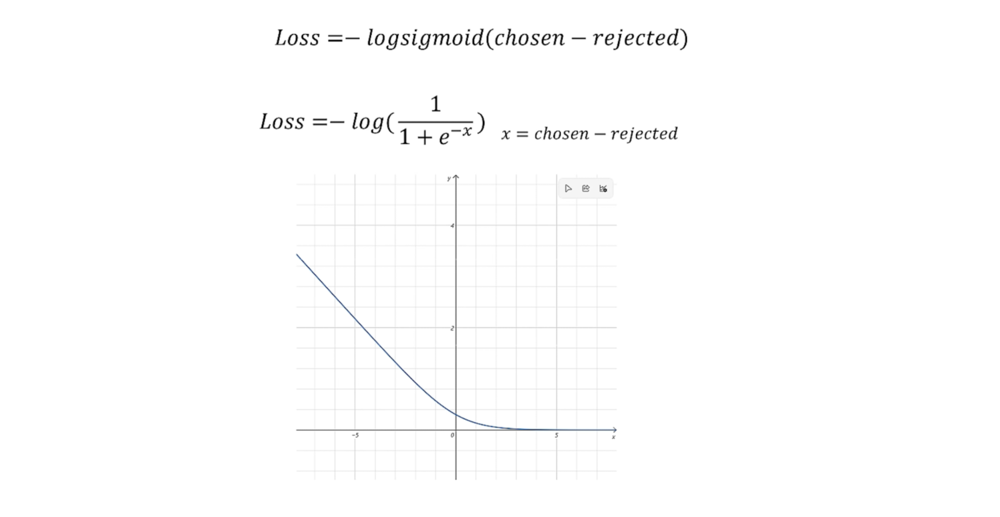

In [34]:
{"question":"Python中的字典是什么？", "chosen":"Python中的字典是一种无序的可变容器，允许使用键-值对来存储数据。","rejected":"Python中的字典用于存储数据。"}
{"question":"什么是回归分析？", "chosen":"回归分析是一种统计方法，用于确定变量之间的关系，通常用于预测和模型拟合。","rejected":"回归分析是一种数据分析方法。"}
{"question":"如何优化机器学习模型？", "chosen":"优化机器学习模型可以通过调节超参数、选择合适的模型和特征工程来实现。","rejected":"优化模型可以提高性能。"}
{"question":"什么是机器学习？", "chosen":"机器学习是一种人工智能方法，通过算法和统计模型使计算机系统能够执行特定任务，而无需明确编程指令。","rejected":"机器学习是计算机科学的一个领域。"}
{"question":"Python的主要特点是什么？", "chosen":"Python的主要特点包括简洁的语法、强大的库支持以及跨平台的兼容性。","rejected":"Python是一种编程语言。"}
{"question":"如何进行数据清洗？", "chosen":"数据清洗通常包括处理缺失值、去除重复数据、标准化数据格式等步骤。","rejected":"数据清洗是数据处理的一部分。"}
{"question":"什么是数据库？", "chosen":"数据库是一个有组织的数据集合，允许高效的数据存储、检索和管理。","rejected":"数据库用于存储数据。"}
{"question":"深度学习和机器学习的区别是什么？", "chosen":"深度学习是机器学习的一个子集，主要通过神经网络处理数据，而传统机器学习算法不依赖于神经网络。","rejected":"深度学习是机器学习的一部分。"}
{"question":"如何使用Pandas加载CSV文件？", "chosen":"你可以使用Pandas的`read_csv()`函数来加载CSV文件，并将其转换为DataFrame。","rejected":"使用Pandas加载CSV文件。"}
{"question":"什么是自然语言处理？", "chosen":"自然语言处理是计算机科学与人工智能的一个子领域，专注于机器与人类语言的交互。","rejected":"自然语言处理是计算机科学的一部分。"}

{'question': '什么是自然语言处理？',
 'chosen': '自然语言处理是计算机科学与人工智能的一个子领域，专注于机器与人类语言的交互。',
 'rejected': '自然语言处理是计算机科学的一部分。'}

### 手撕Reward Model训练

In [ ]:
# 导入PyTorch深度学习框架
import torch
# 导入Hugging Face数据集处理库
from datasets import Dataset
# 导入JSON数据处理库
import json

# 导入PEFT（Parameter-Efficient Fine-Tuning）相关组件，用于高效微调
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training
# 导入Transformers库相关组件，用于加载预训练模型和分词器
from transformers import AutoTokenizer, BitsAndBytesConfig, AutoModelForSequenceClassification
# 导入TRL（Transformer Reinforcement Learning）库，用于奖励模型训练
from trl import RewardTrainer, RewardConfig

# 定义预训练模型的路径（需要用户替换为实际路径）
model_path = r'your_model_path'
# 从预训练模型路径加载分词器，禁用快速分词器以确保兼容性
tokenizer = AutoTokenizer.from_pretrained(model_path, use_fast=False)
# 设置填充方向为右侧填充
tokenizer.padding_side = "right"
# 将结束标记设置为填充标记
tokenizer.pad_token = tokenizer.eos_token

# 配置4位量化参数，用于减少模型内存占用
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,  # 启用4位量化
    bnb_4bit_use_double_quant=True,  # 使用双重量化进一步压缩
    bnb_4bit_quant_type="nf4",  # 使用nf4量化类型
    bnb_4bit_compute_dtype=torch.float16  # 计算时使用float16精度
)

# 从预训练模型路径加载序列分类模型，配置为单标签分类
model = AutoModelForSequenceClassification.from_pretrained(model_path,
                                                           num_labels=1,  # 输出标签数为1（奖励分数）
                                                           quantization_config=bnb_config)  # 应用量化配置
# 设置模型的填充标记ID与分词器保持一致
model.config.pad_token_id = tokenizer.pad_token_id

# 配置LoRA（Low-Rank Adaptation）参数，用于高效微调
peft_config = LoraConfig(
    r=8,  # LoRA的秩，控制适配器的复杂度
    target_modules=["q_proj",  # 目标模块：查询投影层
                    "v_proj",  # 值投影层
                    "k_proj",  # 键投影层
                    "o_proj",  # 输出投影层
                    "gate_proj",  # 门控投影层
                    "down_proj",  # 下投影层
                    "up_proj"  # 上投影层
                    ],
    task_type=TaskType.SEQ_CLS,  # 任务类型：序列分类
    lora_alpha=16,  # LoRA的缩放参数
    lora_dropout=0.05  # LoRA的dropout率
)

# 为4位量化训练准备模型
model = prepare_model_for_kbit_training(model)
# 将LoRA适配器应用到模型上
model = get_peft_model(model, peft_config)
# 打印可训练参数的数量和比例
model.print_trainable_parameters()

# 初始化数据列表
items = []
# 读取偏好数据文件，每行包含一个问题、一个优选答案和一个被拒绝答案
with open("./data/preference.json", "r", encoding="utf8") as f:
    for line in f:
        item = json.loads(line)  # 解析JSON格式的数据
        items.append(item)  # 将数据项添加到列表中

# 将数据列表转换为Hugging Face数据集格式
dataset = Dataset.from_list(items)

# 定义数据预处理函数，将原始数据转换为模型训练所需的格式
def process_func(example):
    # 将问题和优选答案拼接
    chosen = example["question"] + example["chosen"]
    # 将问题和被拒绝答案拼接
    rejected = example["question"] + example["rejected"]

    # 对优选答案进行分词处理
    tokenized_chosen = tokenizer(chosen)
    # 对被拒绝答案进行分词处理
    tokenized_rejected = tokenizer(rejected)

    # 创建新的数据格式
    new_example = {}
    # 存储优选答案的输入ID
    new_example["input_ids_chosen"] = tokenized_chosen["input_ids"]
    # 存储优选答案的注意力掩码
    new_example["attention_mask_chosen"] = tokenized_chosen["attention_mask"]
    # 存储被拒绝答案的输入ID
    new_example["input_ids_rejected"] = tokenized_rejected["input_ids"]
    # 存储被拒绝答案的注意力掩码
    new_example["attention_mask_rejected"] = tokenized_rejected["attention_mask"]
    return new_example

# 对数据集应用预处理函数，移除原始列并添加处理后的列
dataset = dataset.map(process_func, remove_columns=['question', 'chosen', 'rejected'])
# 打印处理后的数据集信息
print(dataset)

# 配置奖励模型训练参数
config = RewardConfig(output_dir="./reward_model")  # 设置输出目录
config.num_train_epochs = 1  # 设置训练轮数为1
config.per_device_train_batch_size = 1  # 设置每个设备的批次大小为1

# 创建奖励模型训练器
trainer = RewardTrainer(
    model=model,  # 传入配置好的模型
    tokenizer=tokenizer,  # 传入分词器
    args=config,  # 传入训练配置
    train_dataset=dataset  # 传入训练数据集
)
# 开始训练奖励模型
trainer.train()
# 保存训练好的奖励模型到指定目录
trainer.save_model("./reward_model")


## 1.2 PPO训练

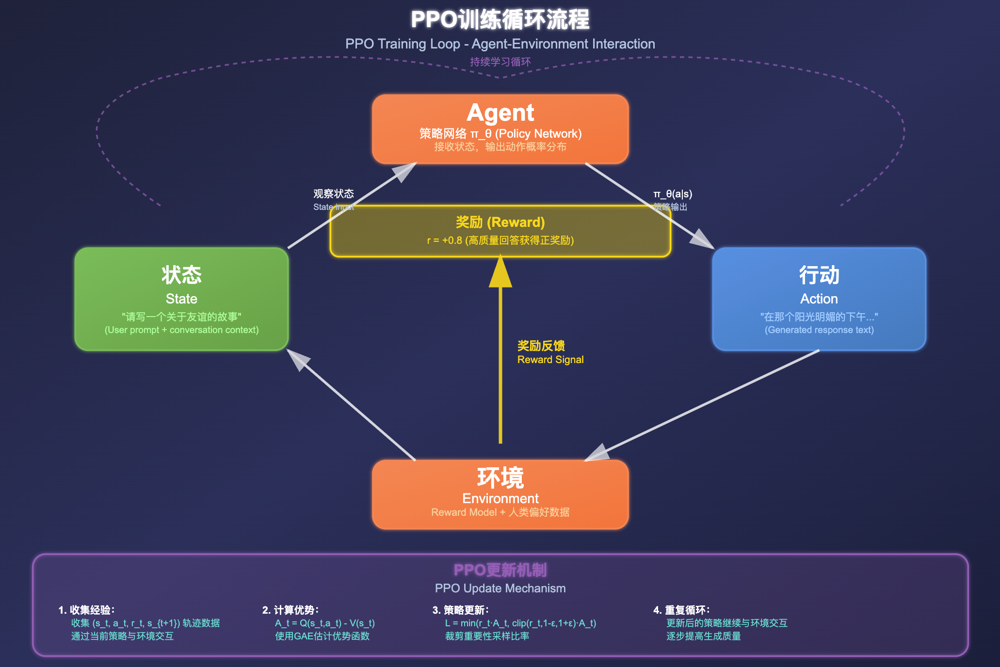

### 用王者荣耀举例什么是PPO

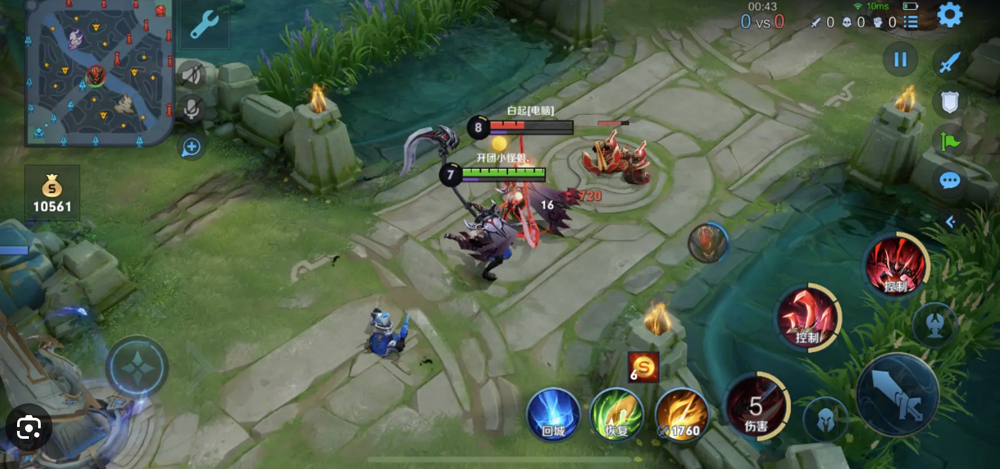

### 训练过程见图解

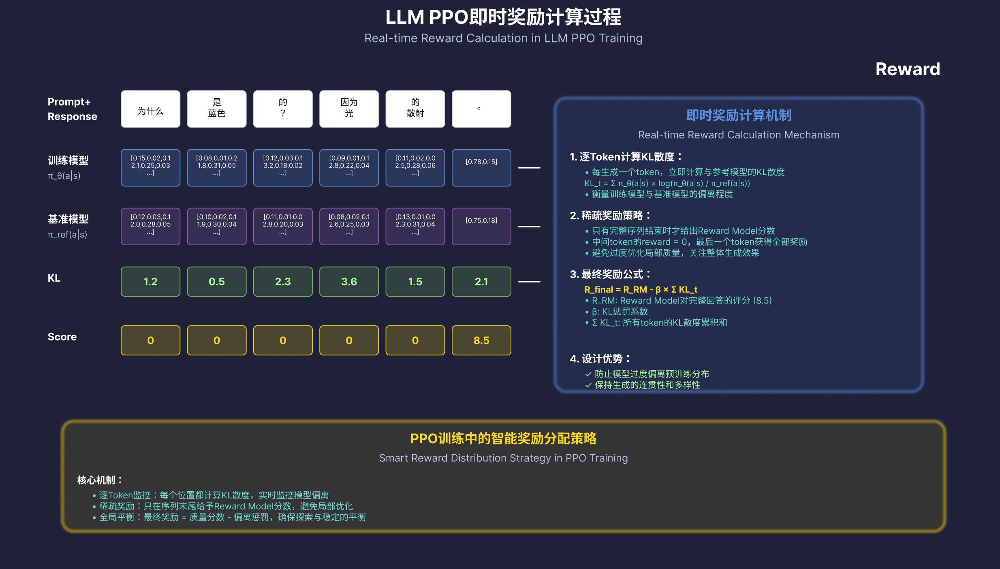

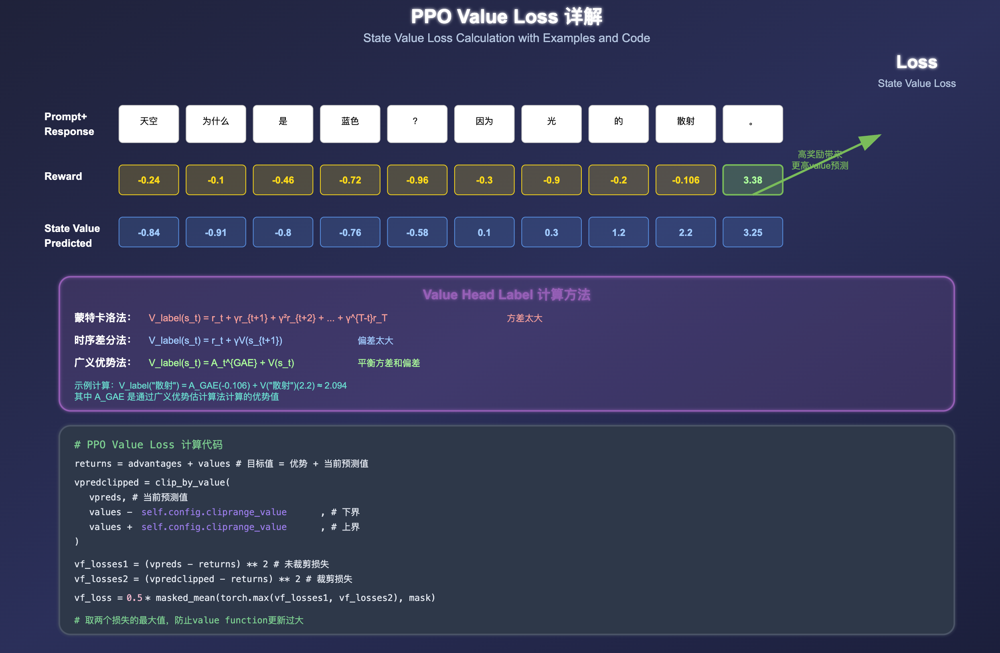

### 但是这样是不是很麻烦？

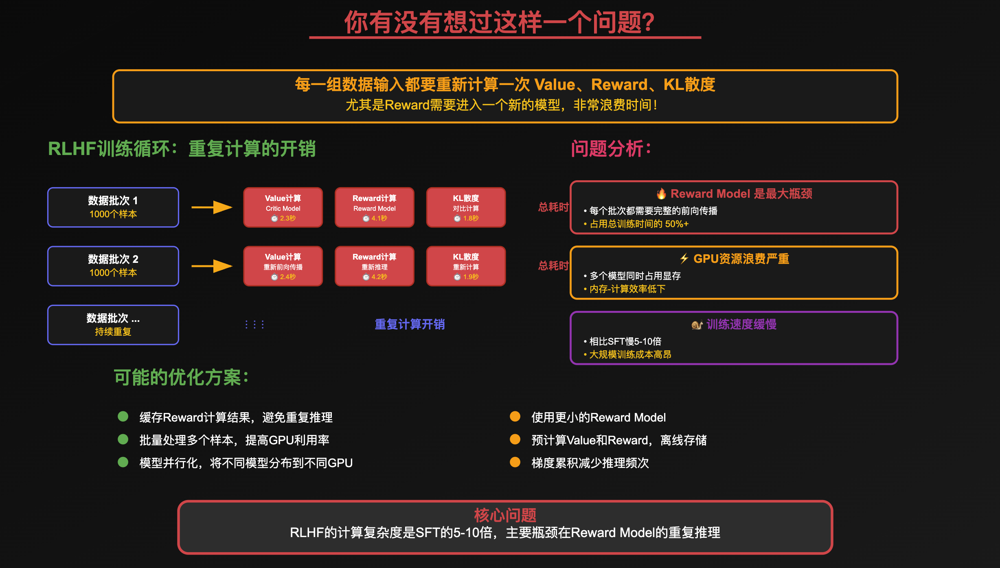

### 这里我们引入一个minibatch的概念

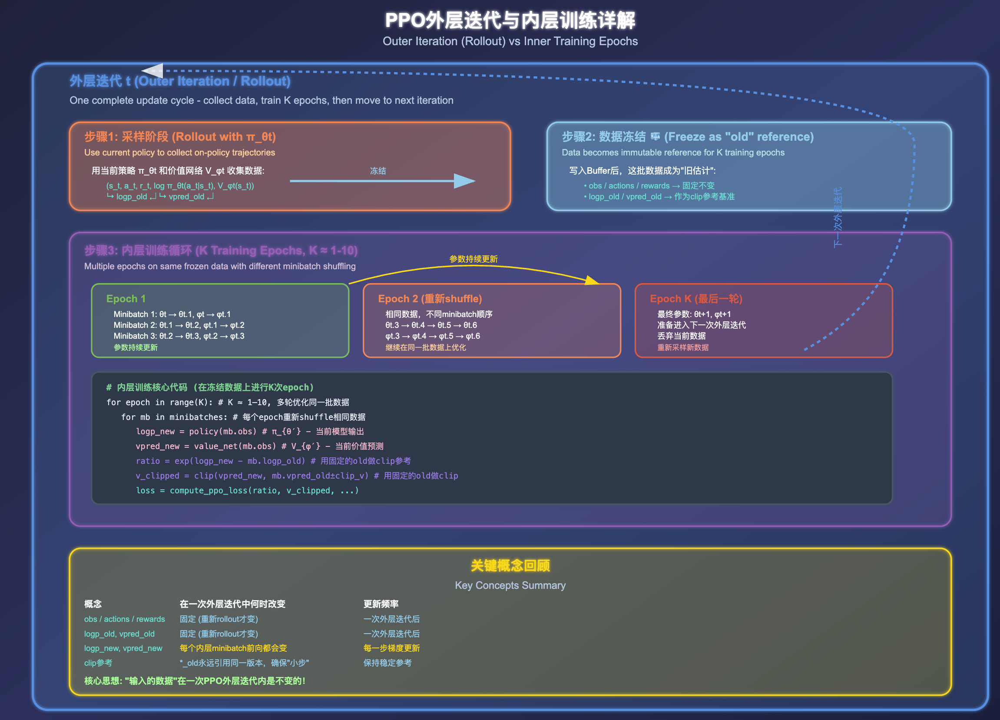

In [ ]:
# 导入PyTorch深度学习框架
import torch
# 导入PEFT（Parameter-Efficient Fine-Tuning）相关组件，用于高效微调
from peft import LoraConfig, TaskType
# 导入Transformers库相关组件，用于加载预训练模型和分词器
from transformers import AutoTokenizer, BitsAndBytesConfig
# 导入TRL（Transformer Reinforcement Learning）库，用于PPO强化学习训练
from trl import AutoModelForCausalLMWithValueHead, PPOConfig, PPOTrainer
# 导入Hugging Face数据集处理库
from datasets import Dataset
# 导入JSON数据处理库
import json

# 定义预训练模型的路径（需要用户替换为实际路径）
model_path = r'your_model_path'
# 从预训练模型路径加载分词器，禁用快速分词器以确保兼容性
tokenizer = AutoTokenizer.from_pretrained(model_path, use_fast=False)
# 设置填充方向为右侧填充
tokenizer.padding_side = "right"
# 将结束标记设置为填充标记
tokenizer.pad_token = tokenizer.eos_token

# 配置4位量化参数，用于减少模型内存占用
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,  # 启用4位量化
    bnb_4bit_use_double_quant=True,  # 使用双重量化进一步压缩
    bnb_4bit_quant_type="nf4",  # 使用nf4量化类型
    bnb_4bit_compute_dtype=torch.bfloat16  # 计算时使用bfloat16精度
)

# 配置LoRA（Low-Rank Adaptation）参数，用于高效微调
peft_config = LoraConfig(
    r=8,  # LoRA的秩，控制适配器的复杂度
    target_modules=["q_proj",  # 目标模块：查询投影层
                    "v_proj",  # 值投影层
                    "k_proj",  # 键投影层
                    "o_proj",  # 输出投影层
                    "gate_proj",  # 门控投影层
                    "down_proj",  # 下投影层
                    "up_proj"  # 上投影层
                    ],
    task_type=TaskType.CAUSAL_LM,  # 任务类型：因果语言模型
    lora_alpha=16,  # LoRA的缩放参数
    lora_dropout=0.05  # LoRA的dropout率
)

# 加载带有价值头的因果语言模型，用于PPO训练
model = AutoModelForCausalLMWithValueHead.from_pretrained(model_path,
                                                          reward_adapter="./reward_model",  # 加载预训练的奖励模型适配器
                                                          peft_config=peft_config,  # 应用LoRA配置
                                                          quantization_config=bnb_config  # 应用量化配置
                                                          )
# 将模型移动到GPU设备上进行计算
model.to("cuda")

# 初始化数据列表
items = []
# 读取查询数据文件，每行包含一个查询问题
with open("./data/queries.json", "r", encoding="utf8") as f:
    for line in f:
        items.append(json.loads(line))  # 解析JSON格式的数据并添加到列表
# 将数据列表转换为Hugging Face数据集格式
queries_dataset = Dataset.from_list(items)

# 定义数据整理函数，将查询文本转换为模型输入格式
def collator(data):
    queries = []  # 初始化查询列表
    for item in data:
        # 对每个查询进行分词处理，转换为张量格式并移动到GPU
        queries.append(tokenizer(item["query"], return_tensors="pt")["input_ids"].squeeze().to("cuda"))
    return queries  # 返回处理后的查询列表

# 配置PPO（Proximal Policy Optimization）训练参数
ppo_config = PPOConfig(kl_penalty="full",  # 使用完整的KL散度惩罚
                       ppo_epochs=3,  # PPO训练轮数为3
                       batch_size=2,  # 批次大小为2
                       mini_batch_size=1)  # 小批次大小为1

# 创建PPO训练器
ppo_trainer = PPOTrainer(config=ppo_config,  # 传入PPO配置
                         model=model,  # 传入模型
                         ref_model=None,  # 参考模型设为None（使用当前模型作为参考）
                         tokenizer=tokenizer,  # 传入分词器
                         dataset=queries_dataset,  # 传入训练数据集
                         data_collator=collator)  # 传入数据整理函数

# 配置文本生成参数
generation_kwargs = {
    "min_length": -1,  # 最小生成长度设为-1（无限制）
    "top_k": 0.0,  # top-k采样设为0（禁用）
    "top_p": 1.0,  # top-p采样设为1.0（使用所有token）
    "do_sample": True,  # 启用采样模式
    "pad_token_id": tokenizer.pad_token_id,  # 设置填充标记ID
    "max_new_tokens": 32,  # 最大生成新token数为32
}

# 开始PPO训练循环
for batch in ppo_trainer.dataloader:
    query_tensors = batch  # 获取当前批次的查询张量

    # 使用模型生成回复
    response_tensors = ppo_trainer.generate(
        query_tensors, return_prompt=False,  **generation_kwargs)
    
    scores = []  # 初始化分数列表
    # 计算每个查询-回复对的奖励分数
    for query, response in zip(query_tensors, response_tensors):
        # 将查询和回复拼接在一起
        input_ids = torch.concat([query, response], dim=0)
        # 增加批次维度
        input_ids = torch.unsqueeze(input_ids, dim=0)
        # 使用奖励模型计算奖励分数
        score = ppo_trainer.model.compute_reward_score(input_ids=input_ids)[0, -1, 0]
        scores.append(score)  # 将分数添加到列表中
    
    # 执行PPO训练步骤，更新模型参数
    stats = ppo_trainer.step(query_tensors, response_tensors, scores)

# 保存训练好的PPO模型
ppo_trainer.save_pretrained("./rl_model")


https://oxpzcwcjtbk.feishu.cn/docx/Cc4wdm1txoxhpBxQcTHcOflunae

# 2. GRPO

每次探索一个，变为每次探索很多个

https://oxpzcwcjtbk.feishu.cn/docx/ViKCdSbPooIsRmxHhW9cTnkjnki

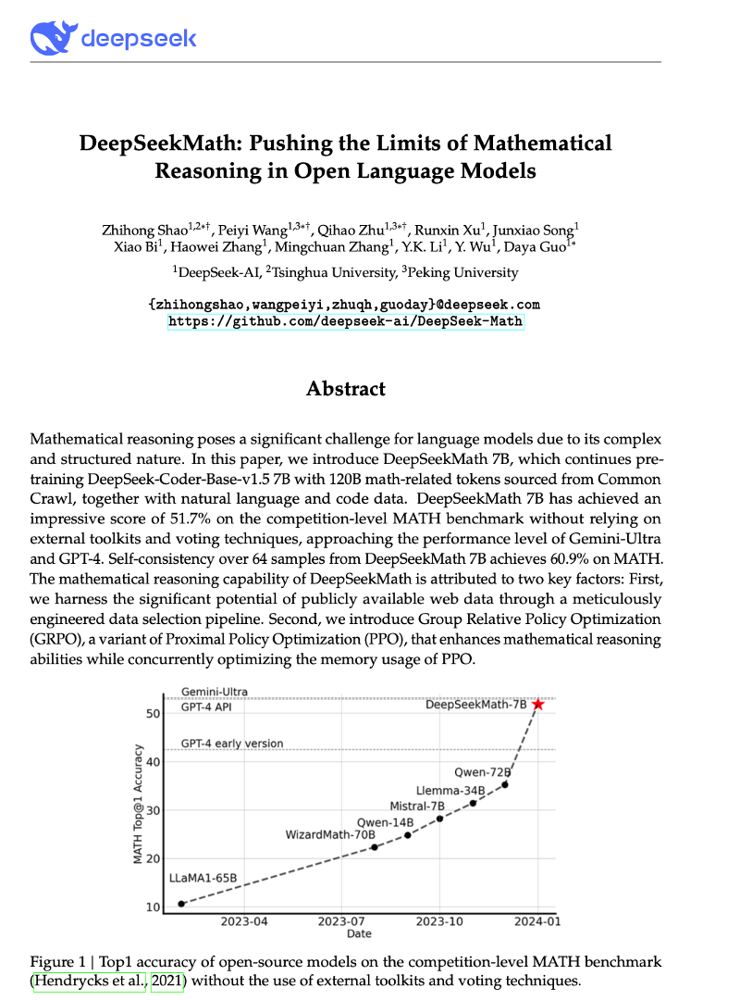

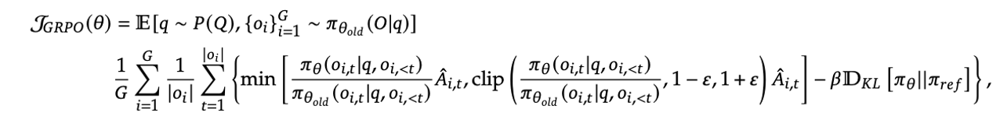

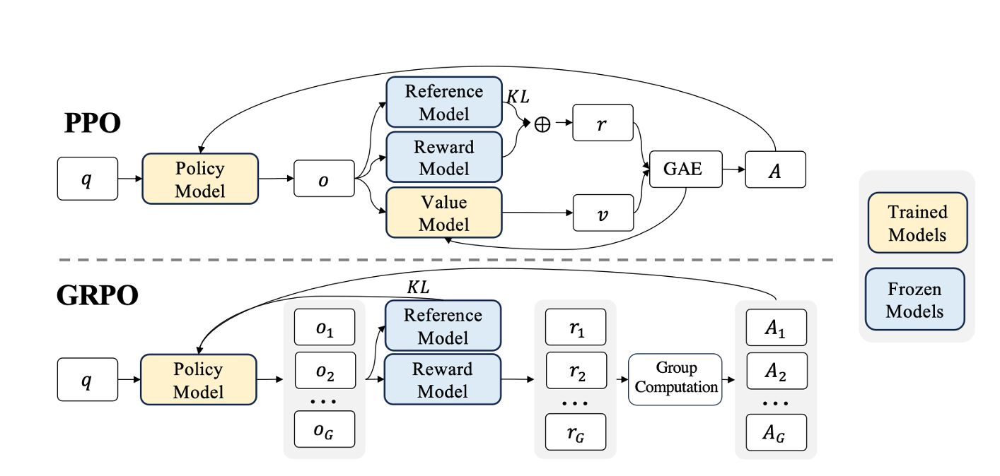

### 具体训练过程见图解

# 3. DPO

# 除了理解DPO的训练过程，原理，还需要理解DPO的数据构造方式，并且能够说清楚怎么迁移到自己的场景里面/

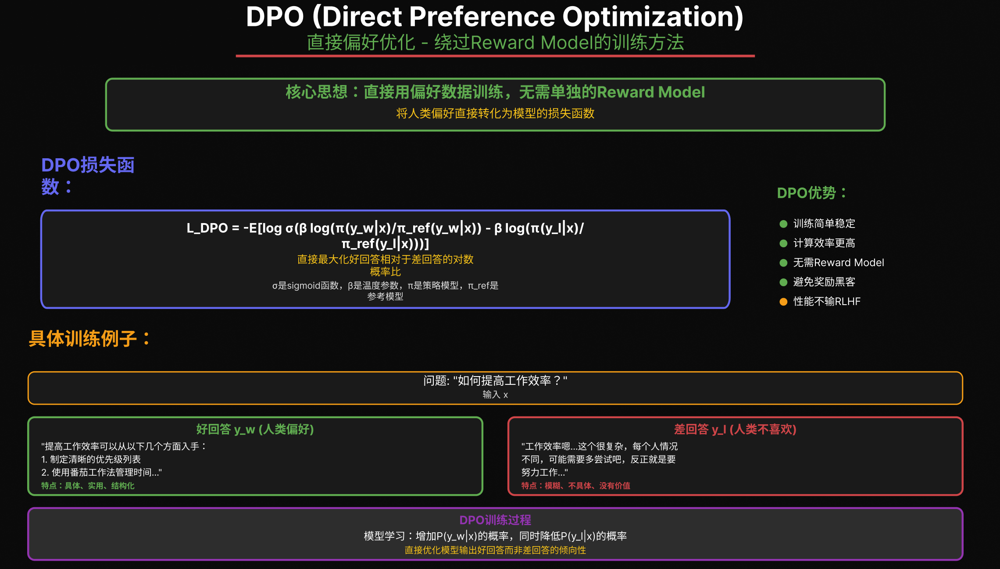

https://oxpzcwcjtbk.feishu.cn/docx/JFxxduIuioQ9foxUUQJcSjicnag

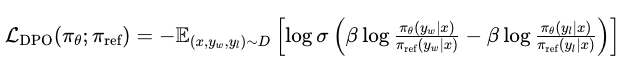

## ！！！一个非常重要的概念，DPO是off policy，所以DPO的采样和当下的模型生成什么无关，而是取决于训练数据

In [51]:
{"question":"Python中的字典是什么？", "chosen":"Python中的字典是一种无序的可变容器，允许使用键-值对来存储数据。","rejected":"Python中的字典用于存储数据。"}
{"question":"什么是回归分析？", "chosen":"回归分析是一种统计方法，用于确定变量之间的关系，通常用于预测和模型拟合。","rejected":"回归分析是一种数据分析方法。"}
{"question":"如何优化机器学习模型？", "chosen":"优化机器学习模型可以通过调节超参数、选择合适的模型和特征工程来实现。","rejected":"优化模型可以提高性能。"}
{"question":"什么是机器学习？", "chosen":"机器学习是一种人工智能方法，通过算法和统计模型使计算机系统能够执行特定任务，而无需明确编程指令。","rejected":"机器学习是计算机科学的一个领域。"}
{"question":"Python的主要特点是什么？", "chosen":"Python的主要特点包括简洁的语法、强大的库支持以及跨平台的兼容性。","rejected":"Python是一种编程语言。"}
{"question":"如何进行数据清洗？", "chosen":"数据清洗通常包括处理缺失值、去除重复数据、标准化数据格式等步骤。","rejected":"数据清洗是数据处理的一部分。"}
{"question":"什么是数据库？", "chosen":"数据库是一个有组织的数据集合，允许高效的数据存储、检索和管理。","rejected":"数据库用于存储数据。"}
{"question":"深度学习和机器学习的区别是什么？", "chosen":"深度学习是机器学习的一个子集，主要通过神经网络处理数据，而传统机器学习算法不依赖于神经网络。","rejected":"深度学习是机器学习的一部分。"}
{"question":"如何使用Pandas加载CSV文件？", "chosen":"你可以使用Pandas的`read_csv()`函数来加载CSV文件，并将其转换为DataFrame。","rejected":"使用Pandas加载CSV文件。"}
{"question":"什么是自然语言处理？", "chosen":"自然语言处理是计算机科学与人工智能的一个子领域，专注于机器与人类语言的交互。","rejected":"自然语言处理是计算机科学的一部分。"}

{'question': '什么是自然语言处理？',
 'chosen': '自然语言处理是计算机科学与人工智能的一个子领域，专注于机器与人类语言的交互。',
 'rejected': '自然语言处理是计算机科学的一部分。'}